## Problem Statement

You need to build a model that is able to classify customer complaints based on the products/services. By doing so, you can segregate these tickets into their relevant categories and, therefore, help in the quick resolution of the issue.

You will be doing topic modelling on the <b>.json</b> data provided by the company. Since this data is not labelled, you need to apply NMF to analyse patterns and classify tickets into the following five clusters based on their products/services:

* Credit card / Prepaid card

* Bank account services

* Theft/Dispute reporting

* Mortgages/loans

* Others


With the help of topic modelling, you will be able to map each ticket onto its respective department/category. You can then use this data to train any supervised model such as logistic regression, decision tree or random forest. Using this trained model, you can classify any new customer complaint support ticket into its relevant department.

## Pipelines that needs to be performed:

You need to perform the following eight major tasks to complete the assignment:

1.  Data loading

2. Text preprocessing

3. Exploratory data analysis (EDA)

4. Feature extraction

5. Topic modelling

6. Model building using supervised learning

7. Model training and evaluation

8. Model inference

## Importing the necessary libraries

In [299]:
import json
import numpy as np
import pandas as pd
import re
import spacy
import string
import en_core_web_sm
nlp = en_core_web_sm.load()
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from plotly.offline import plot
import plotly.graph_objects as go
import plotly.express as px

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from pprint import pprint
from sklearn.decomposition import NMF


## Loading the data

The data is in JSON format and we need to convert it to a dataframe.

In [300]:
# Opening JSON file
f = open("complaints-2021-05-14_08_16.json")

# returns JSON object as a dictionary
data = json.load(f)
df=pd.json_normalize(data)

## Data preparation

In [301]:
# Inspect the dataframe to understand the given data.

# Shape: rows and columns
print("Shape:", df.shape)

df.info()

# First few rows
df.head()



Shape: (78313, 22)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 78313 entries, 0 to 78312
Data columns (total 22 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   _index                             78313 non-null  object 
 1   _type                              78313 non-null  object 
 2   _id                                78313 non-null  object 
 3   _score                             78313 non-null  float64
 4   _source.tags                       10900 non-null  object 
 5   _source.zip_code                   71556 non-null  object 
 6   _source.complaint_id               78313 non-null  object 
 7   _source.issue                      78313 non-null  object 
 8   _source.date_received              78313 non-null  object 
 9   _source.state                      76322 non-null  object 
 10  _source.consumer_disputed          78313 non-null  object 
 11  _source.product                    

,_index,_type,_id,_score,_source.tags,_source.zip_code,_source.complaint_id,_source.issue,_source.date_received,_source.state,...,_source.company_response,_source.company,_source.submitted_via,_source.date_sent_to_company,_source.company_public_response,_source.sub_product,_source.timely,_source.complaint_what_happened,_source.sub_issue,_source.consumer_consent_provided
0,complaint-public-v2,complaint,3211475,0.0,None,90301,3211475,Attempts to collect debt not owed,2019-04-13T12:00:00-05:00,CA,...,Closed with explanation,JPMORGAN CHASE & CO.,Web,2019-04-13T12:00:00-05:00,None,Credit card debt,Yes,,Debt is not yours,Consent not provided
1,complaint-public-v2,complaint,3229299,0.0,Servicemember,319XX,3229299,Written notification about debt,2019-05-01T12:00:00-05:00,GA,...,Closed with explanation,JPMORGAN CHASE & CO.,Web,2019-05-01T12:00:00-05:00,None,Credit card debt,Yes,Good morning my name is XXXX XXXX and I apprec...,Didn't receive enough information to verify debt,Consent provided
2,complaint-public-v2,complaint,3199379,0.0,None,77069,3199379,"Other features, terms, or problems",2019-04-02T12:00:00-05:00,TX,...,Closed with explanation,JPMORGAN CHASE & CO.,Web,2019-04-02T12:00:00-05:00,None,General-purpose credit card or charge card,Yes,I upgraded my XXXX XXXX card in XX/XX/2018 and...,Problem with rewards from credit card,Consent provided
3,complaint-public-v2,complaint,2673060,0.0,None,48066,2673060,Trouble during payment process,2017-09-13T12:00:00-05:00,MI,...,Closed with explanation,JPMORGAN CHASE & CO.,Web,2017-09-14T12:00:00-05:00,None,Conventional home mortgage,Yes,,None,Consent not provided
4,complaint-public-v2,complaint,3203545,0.0,None,10473,3203545,Fees or interest,2019-04-05T12:00:00-05:00,NY,...,Closed with explanation,JPMORGAN CHASE & CO.,Referral,2019-04-05T12:00:00-05:00,None,General-purpose credit card or charge card,Yes,,Charged too much interest,N/A


In [302]:
#print the column names
print(df.columns.tolist())

['_index', '_type', '_id', '_score', '_source.tags', '_source.zip_code', '_source.complaint_id', '_source.issue', '_source.date_received', '_source.state', '_source.consumer_disputed', '_source.product', '_source.company_response', '_source.company', '_source.submitted_via', '_source.date_sent_to_company', '_source.company_public_response', '_source.sub_product', '_source.timely', '_source.complaint_what_happened', '_source.sub_issue', '_source.consumer_consent_provided']


In [303]:
#Assign new column names — strip the '_source.' prefix from nested JSON columns
df.columns = [col.replace('_source.', '') for col in df.columns]
print(df.columns.tolist())


['_index', '_type', '_id', '_score', 'tags', 'zip_code', 'complaint_id', 'issue', 'date_received', 'state', 'consumer_disputed', 'product', 'company_response', 'company', 'submitted_via', 'date_sent_to_company', 'company_public_response', 'sub_product', 'timely', 'complaint_what_happened', 'sub_issue', 'consumer_consent_provided']


In [304]:
#Assign nan in place of blanks in the complaints column
df['complaint_what_happened'] = df['complaint_what_happened'].replace('', np.nan)
print("Null complaints after replacing blanks:", df['complaint_what_happened'].isnull().sum())

Null complaints after replacing blanks: 57241


In [305]:
#Remove all rows where complaints column is nan
df = df.dropna(subset=['complaint_what_happened'])
df = df.reset_index(drop=True)
print("Shape after removing null complaints:", df.shape)

Shape after removing null complaints: (21072, 22)


## Prepare the text for topic modeling

Once you have removed all the blank complaints, you need to:

* Make the text lowercase
* Remove text in square brackets
* Remove punctuation
* Remove words containing numbers


Once you have done these cleaning operations you need to perform the following:
* Lemmatize the texts
* Extract the POS tags of the lemmatized text and remove all the words which have tags other than NN[tag == "NN"].


In [306]:
# Write your function here to clean the text and remove all the unnecessary elements.

def clean_text(text):
    text = text.lower()                                                         # lowercase
    text = re.sub(r'\[.*?\]', '', text)                                         # remove text in square brackets
    text = re.sub(r'[%s]' % re.escape(string.punctuation), '', text)           # remove punctuation
    text = re.sub(r'\w*\d\w*', '', text)                                        # remove words containing numbers
    text = re.sub(r'\s+', ' ', text).strip()                                    # collapse extra whitespace
    return text

In [307]:
# Write your function to Lemmatize the texts

# Uses spaCy: token.lemma_ gives the base form (e.g. "running" → "run", pronouns → "-PRON-")

def lemmatize_text(text):
    doc = nlp(text)
    return " ".join([token.lemma_ for token in doc])

In [308]:
# Create a dataframe('df_clean') that will have only the complaints and the lemmatized complaints

df_clean = df[['complaint_what_happened']].copy()

# Apply cleaning, then lemmatization
df_clean['complaint_what_happened'] = df_clean['complaint_what_happened'].apply(clean_text)
df_clean['lemmatized_complaints']   = df_clean['complaint_what_happened'].apply(lemmatize_text)

print("Shape:", df_clean.shape)
df_clean.head()

Shape: (21072, 2)


,complaint_what_happened,lemmatized_complaints
0,good morning my name is xxxx xxxx and i apprec...,good morning my name be xxxx xxxx and I apprec...
1,i upgraded my xxxx xxxx card in and was told b...,I upgrade my xxxx xxxx card in and be tell by ...
2,chase card was reported on however fraudulent ...,chase card be report on however fraudulent app...
3,on while trying to book a xxxx xxxx ticket i c...,on while try to book a xxxx xxxx ticket I come...
4,my grand son give me check for i deposit it in...,my grand son give I check for I deposit it int...


In [309]:
df_clean

,complaint_what_happened,lemmatized_complaints
0,good morning my name is xxxx xxxx and i apprec...,good morning my name be xxxx xxxx and I apprec...
1,i upgraded my xxxx xxxx card in and was told b...,I upgrade my xxxx xxxx card in and be tell by ...
2,chase card was reported on however fraudulent ...,chase card be report on however fraudulent app...
3,on while trying to book a xxxx xxxx ticket i c...,on while try to book a xxxx xxxx ticket I come...
4,my grand son give me check for i deposit it in...,my grand son give I check for I deposit it int...
...,...,...
21067,after being a chase card customer for well ove...,after be a chase card customer for well over a...
21068,on wednesday xxxxxxxx i called chas my xxxx xx...,on wednesday xxxxxxxx I call chas my xxxx xxxx...
21069,i am not familiar with xxxx pay and did not un...,I be not familiar with xxxx pay and do not und...
21070,i have had flawless credit for yrs ive had cha...,I have have flawless credit for yrs I ve have ...


In [310]:
# Write your function to extract the POS tags

# Uses spaCy token.tag_ (Penn Treebank tags) to keep only singular common nouns (NN)

def pos_tag(text):
    doc = nlp(text)
    return " ".join([token.text for token in doc if token.tag_ == "NN"])


df_clean["complaint_POS_removed"] = df_clean["lemmatized_complaints"].apply(pos_tag)

In [311]:
#The clean dataframe should now contain the raw complaint, lemmatized complaint and the complaint after removing POS tags.
df_clean

,complaint_what_happened,lemmatized_complaints,complaint_POS_removed
0,good morning my name is xxxx xxxx and i apprec...,good morning my name be xxxx xxxx and I apprec...,morning name stop service debt verification st...
1,i upgraded my xxxx xxxx card in and was told b...,I upgrade my xxxx xxxx card in and be tell by ...,card agent anniversary date agent information ...
2,chase card was reported on however fraudulent ...,chase card be report on however fraudulent app...,chase card report application identity consent...
3,on while trying to book a xxxx xxxx ticket i c...,on while try to book a xxxx xxxx ticket I come...,ticket offer ticket reward card information of...
4,my grand son give me check for i deposit it in...,my grand son give I check for I deposit it int...,son chase account fund chase bank account mone...
...,...,...,...
21067,after being a chase card customer for well ove...,after be a chase card customer for well over a...,chase card customer decade solicitation credit...
21068,on wednesday xxxxxxxx i called chas my xxxx xx...,on wednesday xxxxxxxx I call chas my xxxx xxxx...,credit card provider claim purchase protection...
21069,i am not familiar with xxxx pay and did not un...,I be not familiar with xxxx pay and do not und...,pay risk consumer chase bank app chase year ba...
21070,i have had flawless credit for yrs ive had cha...,I have have flawless credit for yrs I ve have ...,credit yrs credit card chase freedom problem b...


## Exploratory data analysis to get familiar with the data.

Write the code in this task to perform the following:

*   Visualise the data according to the 'Complaint' character length
*   Using a word cloud find the top 40 words by frequency among all the articles after processing the text
*   Find the top unigrams,bigrams and trigrams by frequency among all the complaints after processing the text. ‘




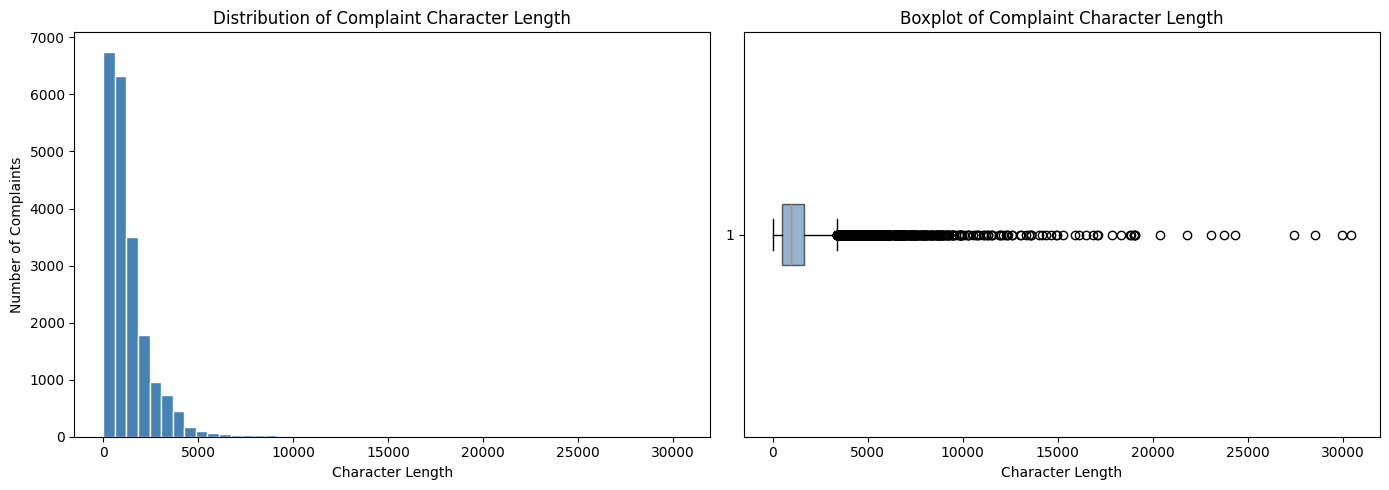

count    21072.000000
mean      1316.561551
std       1430.207569
min          0.000000
25%        500.000000
50%        936.000000
75%       1653.250000
max      30452.000000
Name: complaint_length, dtype: float64


In [312]:
# Visualise the data according to the 'Complaint' character length

df_clean['complaint_length'] = df_clean['complaint_what_happened'].apply(len)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(df_clean['complaint_length'], bins=50, color='steelblue', edgecolor='white')
axes[0].set_xlabel('Character Length')
axes[0].set_ylabel('Number of Complaints')
axes[0].set_title('Distribution of Complaint Character Length')

# Box plot to spot outliers
axes[1].boxplot(df_clean['complaint_length'], vert=False, patch_artist=True,
                boxprops=dict(facecolor='steelblue', alpha=0.6))
axes[1].set_xlabel('Character Length')
axes[1].set_title('Boxplot of Complaint Character Length')

plt.tight_layout()
plt.show()

print(df_clean['complaint_length'].describe())

#### Find the top 40 words by frequency among all the articles after processing the text.

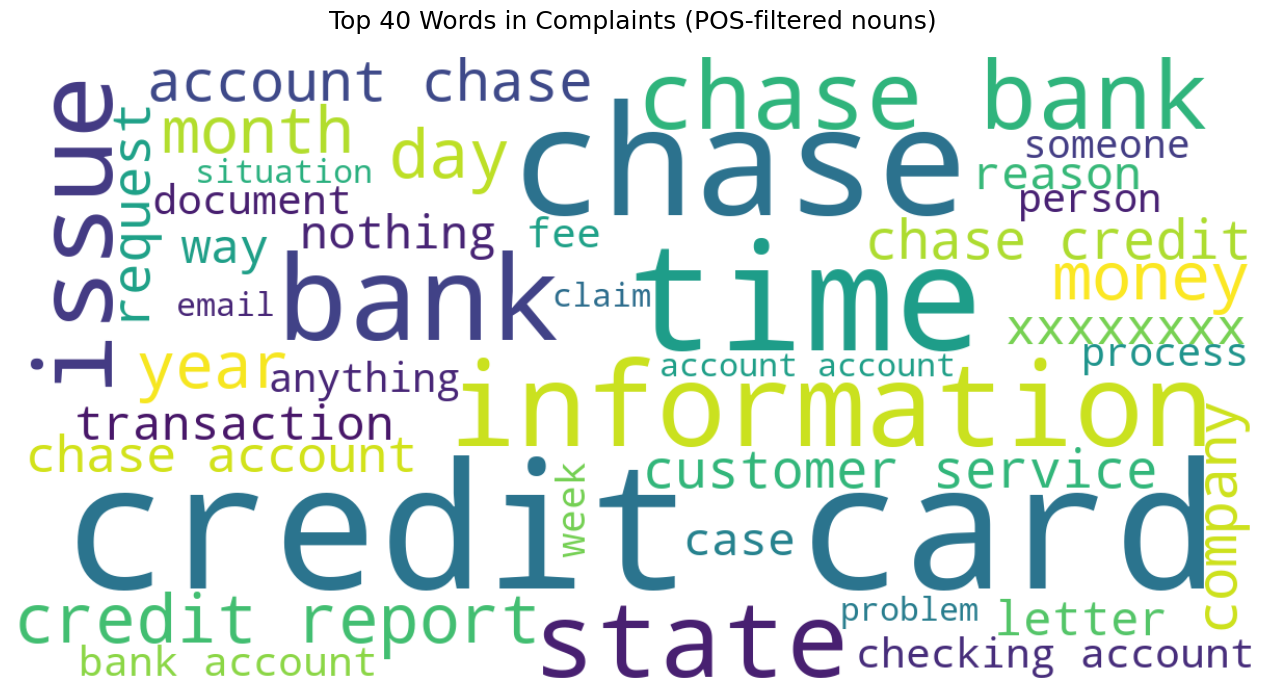

In [313]:
# Using a word cloud find the top 40 words by frequency among all the articles after processing the text

from wordcloud import WordCloud

all_words = ' '.join(df_clean['complaint_POS_removed'].dropna())

wordcloud = WordCloud(
    width=1200, height=600,
    max_words=40,
    background_color='white',
    colormap='viridis'
).generate(all_words)

plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Top 40 Words in Complaints (POS-filtered nouns)', fontsize=18, pad=20)
plt.tight_layout()
plt.show()

In [314]:
#Removing -PRON- from the text corpus
df_clean['Complaint_clean'] = df_clean['complaint_POS_removed'].str.replace('-PRON-', '')

#### Find the top unigrams,bigrams and trigrams by frequency among all the complaints after processing the text.

In [315]:
# Top 30 unigram frequency among the complaints in the cleaned dataframe (df_clean)

cv_uni = CountVectorizer(ngram_range=(1, 1), max_features=30)
uni_matrix = cv_uni.fit_transform(df_clean['Complaint_clean'].dropna())

try:
    uni_words = cv_uni.get_feature_names_out()
except AttributeError:
    uni_words = cv_uni.get_feature_names()

uni_freq = pd.DataFrame({
    'word': uni_words,
    'count': uni_matrix.toarray().sum(axis=0)
}).sort_values('count', ascending=False).reset_index(drop=True)

   word  count
  chase  59312
account  46965
 credit  33457
   card  30143
   bank  21392
payment  21140
   time  15978
 charge  14715
    day  12904
  money  11921


/var/folders/g0/cnfj_ddd3f9gtnjhpp8_krt80000gn/T/ipykernel_15828/3292649742.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=uni_freq.head(10), x='count', y='word', palette='Blues_r')


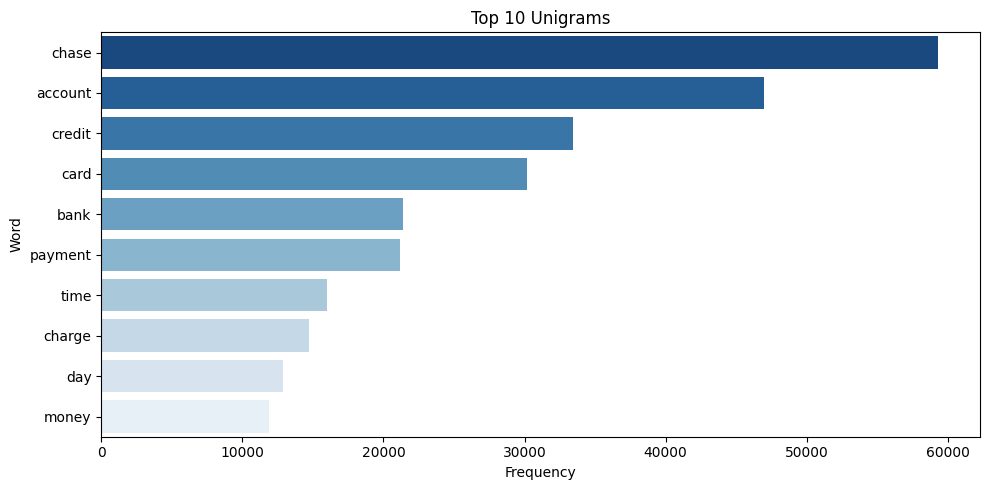

In [316]:
# Print the top 10 words in the unigram frequency

print(uni_freq.head(10).to_string(index=False))

plt.figure(figsize=(10, 5))
sns.barplot(data=uni_freq.head(10), x='count', y='word', palette='Blues_r')
plt.title('Top 10 Unigrams')
plt.xlabel('Frequency')
plt.ylabel('Word')
plt.tight_layout()
plt.show()

In [317]:
# Top 30 bigram frequency among the complaints in the cleaned dataframe (df_clean)

cv_bi = CountVectorizer(ngram_range=(2, 2), max_features=30)
bi_matrix = cv_bi.fit_transform(df_clean['Complaint_clean'].dropna())

try:
    bi_words = cv_bi.get_feature_names_out()
except AttributeError:
    bi_words = cv_bi.get_feature_names()

bi_freq = pd.DataFrame({
    'word': bi_words,
    'count': bi_matrix.toarray().sum(axis=0)
}).sort_values('count', ascending=False).reset_index(drop=True)

            word  count
     credit card  12824
      chase bank   4050
   credit report   3948
   account chase   3364
    chase credit   3121
customer service   3061
   chase account   2757
checking account   2456
    bank account   2401
 account account   2241


/var/folders/g0/cnfj_ddd3f9gtnjhpp8_krt80000gn/T/ipykernel_15828/3916129554.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=bi_freq.head(10), x='count', y='word', palette='Greens_r')


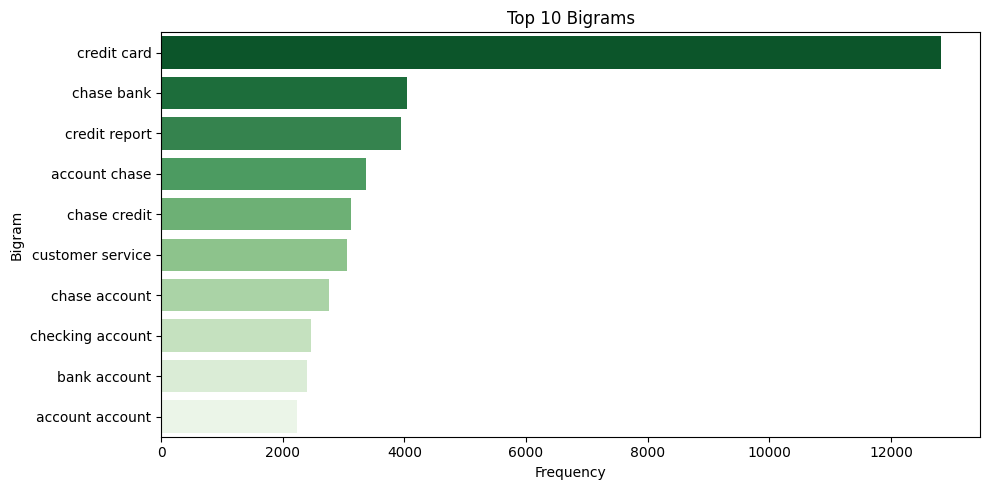

In [318]:
# Print the top 10 words in the bigram frequency

print(bi_freq.head(10).to_string(index=False))

plt.figure(figsize=(10, 5))
sns.barplot(data=bi_freq.head(10), x='count', y='word', palette='Greens_r')
plt.title('Top 10 Bigrams')
plt.xlabel('Frequency')
plt.ylabel('Bigram')
plt.tight_layout()
plt.show()

In [319]:
# Top 30 trigram frequency among the complaints in the cleaned dataframe (df_clean)

cv_tri = CountVectorizer(ngram_range=(3, 3), max_features=30)
tri_matrix = cv_tri.fit_transform(df_clean['Complaint_clean'].dropna())

try:
    tri_words = cv_tri.get_feature_names_out()
except AttributeError:
    tri_words = cv_tri.get_feature_names()

tri_freq = pd.DataFrame({
    'word': tri_words,
    'count': tri_matrix.toarray().sum(axis=0)
}).sort_values('count', ascending=False).reset_index(drop=True)

                  word  count
     chase credit card   2131
   credit card account   1071
   credit card company    987
     credit card chase    800
chase customer service    606
 inquiry credit report    512
    credit card credit    488
    chase bank account    436
   account credit card    419
    charge credit card    398


/var/folders/g0/cnfj_ddd3f9gtnjhpp8_krt80000gn/T/ipykernel_15828/167407202.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=tri_freq.head(10), x='count', y='word', palette='Oranges_r')


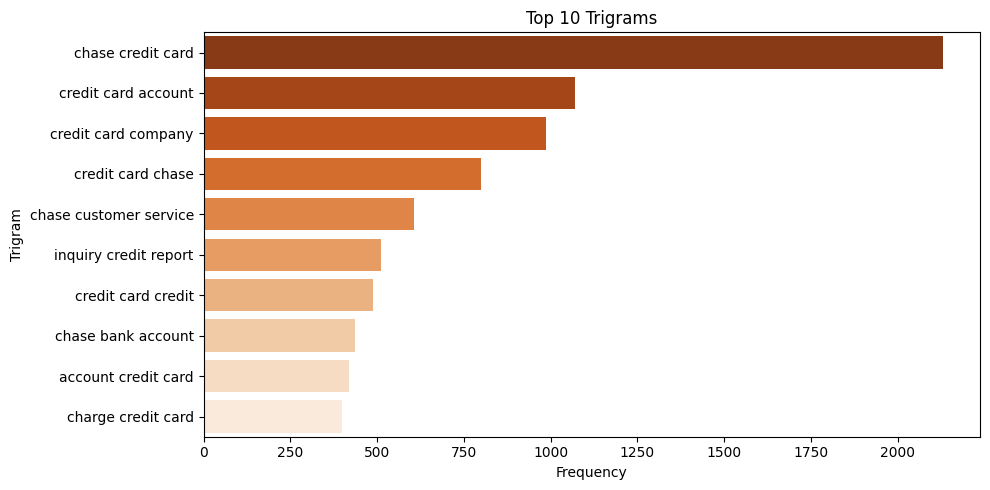

In [320]:
# Print the top 10 words in the trigram frequency

print(tri_freq.head(10).to_string(index=False))

plt.figure(figsize=(10, 5))
sns.barplot(data=tri_freq.head(10), x='count', y='word', palette='Oranges_r')
plt.title('Top 10 Trigrams')
plt.xlabel('Frequency')
plt.ylabel('Trigram')
plt.tight_layout()
plt.show()

## The personal details of customer has been masked in the dataset with xxxx. Let's remove the masked text as this will be of no use for our analysis

In [321]:
df_clean['Complaint_clean'] = df_clean['Complaint_clean'].str.replace('xxxx','')

In [322]:
#All masked texts has been removed
df_clean

,complaint_what_happened,lemmatized_complaints,complaint_POS_removed,complaint_length,Complaint_clean
0,good morning my name is xxxx xxxx and i apprec...,good morning my name be xxxx xxxx and I apprec...,morning name stop service debt verification st...,469,morning name stop service debt verification st...
1,i upgraded my xxxx xxxx card in and was told b...,I upgrade my xxxx xxxx card in and be tell by ...,card agent anniversary date agent information ...,334,card agent anniversary date agent information ...
2,chase card was reported on however fraudulent ...,chase card be report on however fraudulent app...,chase card report application identity consent...,209,chase card report application identity consent...
3,on while trying to book a xxxx xxxx ticket i c...,on while try to book a xxxx xxxx ticket I come...,ticket offer ticket reward card information of...,1424,ticket offer ticket reward card information of...
4,my grand son give me check for i deposit it in...,my grand son give I check for I deposit it int...,son chase account fund chase bank account mone...,452,son chase account fund chase bank account mone...
...,...,...,...,...,...
21067,after being a chase card customer for well ove...,after be a chase card customer for well over a...,chase card customer decade solicitation credit...,639,chase card customer decade solicitation credit...
21068,on wednesday xxxxxxxx i called chas my xxxx xx...,on wednesday xxxxxxxx I call chas my xxxx xxxx...,credit card provider claim purchase protection...,2055,credit card provider claim purchase protection...
21069,i am not familiar with xxxx pay and did not un...,I be not familiar with xxxx pay and do not und...,pay risk consumer chase bank app chase year ba...,2294,pay risk consumer chase bank app chase year ba...
21070,i have had flawless credit for yrs ive had cha...,I have have flawless credit for yrs I ve have ...,credit yrs credit card chase freedom problem b...,1961,credit yrs credit card chase freedom problem b...


## Feature Extraction
Convert the raw texts to a matrix of TF-IDF features

**max_df** is used for removing terms that appear too frequently, also known as "corpus-specific stop words"
max_df = 0.95 means "ignore terms that appear in more than 95% of the complaints"

**min_df** is used for removing terms that appear too infrequently
min_df = 2 means "ignore terms that appear in less than 2 complaints"

In [323]:
# Initialise the TfidfVectorizer
# max_df=0.95 → ignore terms appearing in >95% of complaints (corpus-specific stop words)
# min_df=2    → ignore terms appearing in fewer than 2 complaints (rare/noisy terms)

tfidf = TfidfVectorizer(max_df=0.95, min_df=2, stop_words='english')
print("TfidfVectorizer initialised:", tfidf)

TfidfVectorizer initialised: TfidfVectorizer(max_df=0.95, min_df=2, stop_words='english')


#### Create a document term matrix using fit_transform

The contents of a document term matrix are tuples of (complaint_id,token_id) tf-idf score:
The tuples that are not there have a tf-idf score of 0

In [324]:
# Create the Document Term Matrix by transforming the complaints column present in df_clean

# fit_transform learns the vocabulary AND converts text → TF-IDF sparse matrix in one step

dtm = tfidf.fit_transform(df_clean['Complaint_clean'].dropna())

print("DTM shape:", dtm.shape)
print("  → rows    : number of complaints")
print("  → columns : number of unique terms (vocabulary size)")
try:
    feature_names = tfidf.get_feature_names_out()
except AttributeError:
    feature_names = tfidf.get_feature_names()

print("\nVocabulary size:", len(feature_names))
print("\nSample DTM (first 5 complaints, first 10 terms):")
print(pd.DataFrame(
    dtm[:5, :10].toarray(),
    columns=feature_names[:10]
))

DTM shape: (21072, 6757)
  → rows    : number of complaints
  → columns : number of unique terms (vocabulary size)

Vocabulary size: 6757

Sample DTM (first 5 complaints, first 10 terms):
    aa  aarp  abandonment  abatement  abbreviation  abet  abide  ability  \
0  0.0   0.0          0.0        0.0           0.0   0.0    0.0      0.0   
1  0.0   0.0          0.0        0.0           0.0   0.0    0.0      0.0   
2  0.0   0.0          0.0        0.0           0.0   0.0    0.0      0.0   
3  0.0   0.0          0.0        0.0           0.0   0.0    0.0      0.0   
4  0.0   0.0          0.0        0.0           0.0   0.0    0.0      0.0   

   abovementione  abovereference  
0            0.0             0.0  
1            0.0             0.0  
2            0.0             0.0  
3            0.0             0.0  
4            0.0             0.0  


## Topic Modelling using NMF

Non-Negative Matrix Factorization (NMF) is an unsupervised technique so there are no labeling of topics that the model will be trained on. The way it works is that, NMF decomposes (or factorizes) high-dimensional vectors into a lower-dimensional representation. These lower-dimensional vectors are non-negative which also means their coefficients are non-negative.

In this task you have to perform the following:

* Find the best number of clusters
* Apply the best number to create word clusters
* Inspect & validate the correction of each cluster wrt the complaints
* Correct the labels if needed
* Map the clusters to topics/cluster names

In [325]:
from sklearn.decomposition import NMF

## Manual Topic Modeling
You need to do take the trial & error approach to find the best num of topics for your NMF model.

The only parameter that is required is the number of components i.e. the number of topics we want. This is the most crucial step in the whole topic modeling process and will greatly affect how good your final topics are.

In [326]:
# Load your nmf_model with the n_components i.e 5
num_topics = 5

# keep the random_state = 43

# NMF decomposes DTM (m×n) into:
#   W  (m × num_topics) — document-topic matrix
#   H  (num_topics × n) — topic-term matrix
nmf_model = NMF(n_components=num_topics, random_state=43)
print("NMF model:", nmf_model)

NMF model: NMF(n_components=5, random_state=43)


In [327]:
nmf_model.fit(dtm)
len(tfidf.get_feature_names_out())

6757

In [328]:
# Print the Top 15 words for each of the topics

try:
    words = np.array(tfidf.get_feature_names_out())
except AttributeError:
    words = np.array(tfidf.get_feature_names())

for topic_idx, component in enumerate(nmf_model.components_):
    top_idx   = component.argsort()[::-1][:15]
    top_words = words[top_idx]
    print(f"Topic {topic_idx} : {', '.join(top_words)}")
    print()

Topic 0 : account, check, bank, money, chase, fund, deposit, day, branch, checking, transaction, number, claim, business, transfer

Topic 1 : card, charge, chase, credit, dispute, fee, transaction, purchase, service, fraud, balance, merchant, time, company, statement

Topic 2 : loan, mortgage, chase, home, modification, property, year, letter, document, time, rate, foreclosure, house, sale, request

Topic 3 : credit, report, inquiry, card, account, score, company, debt, information, reporting, identity, application, bureau, theft, limit

Topic 4 : payment, balance, month, fee, statement, day, time, auto, chase, date, credit, account, year, mortgage, error



In [329]:
# Create the best topic for each complaint as integer value 0, 1, 2, 3 or 4

# nmf_model.transform(dtm) returns W — the document-topic matrix
# Shape: (num_complaints × num_topics)
# Each value = how strongly that complaint belongs to that topic

topic_matrix = nmf_model.fit_transform(dtm)

# argmax picks the column (topic) with the highest score for each row (complaint)
best_topics = topic_matrix.argmax(axis=1)

print("Topic distribution across all complaints:")
print(pd.Series(best_topics).value_counts().sort_index())
print()
print("Sample topic scores for first complaint (one score per topic):")
print(topic_matrix[0])

Topic distribution across all complaints:
0    5644
1    6299
2    3865
3    2876
4    2388
Name: count, dtype: int64

Sample topic scores for first complaint (one score per topic):
[0.01903174 0.00379001 0.02131856 0.01528558 0.00869362]


In [330]:
# Assign the best topic to each complaint
df_clean['Topic'] = best_topics
df_clean.head()

,complaint_what_happened,lemmatized_complaints,complaint_POS_removed,complaint_length,Complaint_clean,Topic
0,good morning my name is xxxx xxxx and i apprec...,good morning my name be xxxx xxxx and I apprec...,morning name stop service debt verification st...,469,morning name stop service debt verification st...,2
1,i upgraded my xxxx xxxx card in and was told b...,I upgrade my xxxx xxxx card in and be tell by ...,card agent anniversary date agent information ...,334,card agent anniversary date agent information ...,1
2,chase card was reported on however fraudulent ...,chase card be report on however fraudulent app...,chase card report application identity consent...,209,chase card report application identity consent...,3
3,on while trying to book a xxxx xxxx ticket i c...,on while try to book a xxxx xxxx ticket I come...,ticket offer ticket reward card information of...,1424,ticket offer ticket reward card information of...,3
4,my grand son give me check for i deposit it in...,my grand son give I check for I deposit it int...,son chase account fund chase bank account mone...,452,son chase account fund chase bank account mone...,0


In [331]:
#Print the first 5 Complaint for each of the Topics
df_clean=df_clean.groupby('Topic').head(10)
df_clean.sort_values('Topic')

,complaint_what_happened,lemmatized_complaints,complaint_POS_removed,complaint_length,Complaint_clean,Topic
12,i opened an account with chase bank on xxxx an...,I open an account with chase bank on xxxx and ...,account bank code bonus term everything accoun...,401,account bank code bonus term everything accoun...,0
29,someone called stating i had felony committed ...,someone call state I have felony commit under ...,someone state felony security number name chec...,174,someone state felony security number name chec...,0
44,on xxxxxxxx i received an advertisement via em...,on xxxxxxxx I receive an advertisement via ema...,advertisement email chase customer chase total...,2486,advertisement email chase customer chase total...,0
4,my grand son give me check for i deposit it in...,my grand son give I check for I deposit it int...,son chase account fund chase bank account mone...,452,son chase account fund chase bank account mone...,0
43,i purchase is an airline ticket on xxxxxxxx an...,I purchase be an airline ticket on xxxxxxxx an...,airline ticket dollar airport ticket hour refu...,1422,airline ticket dollar airport ticket hour refu...,0
6,with out notice jp morgan chase restricted my ...,with out notice jp morgan chase restrict my ac...,notice account debit card branch customer serv...,2221,notice account debit card branch customer serv...,0
17,my card went missing and i didnt realize it un...,my card go missing and I do not realize it unt...,card today email deposit money bank account gone,176,card today email deposit money bank account gone,0
37,in several transactions on my chase checking a...,in several transaction on my chase checking ac...,transaction chase checking account report chas...,526,transaction chase checking account report chas...,0
10,mishandling of this account by chase auto and ...,mishandle of this account by chase auto and xxxx,mishandle account auto,50,mishandle account auto,0
15,i opened the saving account for the bonus i wa...,I open the save account for the bonus I be sup...,save account bonus bonus auto transfer check t...,481,save account bonus bonus auto transfer check t...,0


#### After evaluating the mapping, if the topics assigned are correct then assign these names to the relevant topic:
* Bank Account services
* Credit card or prepaid card
* Theft/Dispute Reporting
* Mortgage/Loan
* Others

In [332]:
# Create the dictionary of Topic names and Topics
# Map each integer (0-9) to the category whose top words best describe it


Topic_names = {
    0: 'Bank Account services',
    1: 'Theft/Dispute Reporting', 
    2: 'Mortgage/Loan',
    3: 'Credit card or prepaid card', 
    4: 'Others'
}

# Replace Topics with Topic Names
df_clean['Topic'] = df_clean['Topic'].map(Topic_names)

print("Topic distribution after naming:")
print(df_clean['Topic'].value_counts())

Topic distribution after naming:
Topic
Mortgage/Loan                  10
Theft/Dispute Reporting        10
Credit card or prepaid card    10
Bank Account services          10
Others                         10
Name: count, dtype: int64


/var/folders/g0/cnfj_ddd3f9gtnjhpp8_krt80000gn/T/ipykernel_15828/2021466065.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['Topic'] = df_clean['Topic'].map(Topic_names)


In [333]:
df_clean.head(10)

,complaint_what_happened,lemmatized_complaints,complaint_POS_removed,complaint_length,Complaint_clean,Topic
0,good morning my name is xxxx xxxx and i apprec...,good morning my name be xxxx xxxx and I apprec...,morning name stop service debt verification st...,469,morning name stop service debt verification st...,Mortgage/Loan
1,i upgraded my xxxx xxxx card in and was told b...,I upgrade my xxxx xxxx card in and be tell by ...,card agent anniversary date agent information ...,334,card agent anniversary date agent information ...,Theft/Dispute Reporting
2,chase card was reported on however fraudulent ...,chase card be report on however fraudulent app...,chase card report application identity consent...,209,chase card report application identity consent...,Credit card or prepaid card
3,on while trying to book a xxxx xxxx ticket i c...,on while try to book a xxxx xxxx ticket I come...,ticket offer ticket reward card information of...,1424,ticket offer ticket reward card information of...,Credit card or prepaid card
4,my grand son give me check for i deposit it in...,my grand son give I check for I deposit it int...,son chase account fund chase bank account mone...,452,son chase account fund chase bank account mone...,Bank Account services
5,can you please remove inquiry,can you please remove inquiry,inquiry,29,inquiry,Credit card or prepaid card
6,with out notice jp morgan chase restricted my ...,with out notice jp morgan chase restrict my ac...,notice account debit card branch customer serv...,2221,notice account debit card branch customer serv...,Bank Account services
7,during the summer months i experience a declin...,during the summer month I experience a decline...,summer month decline income employment month p...,1342,summer month decline income employment month p...,Others
8,on xxxx i made a payment to an online retailer...,on xxxx I make a payment to an online retailer...,payment retailer use chase pay chase website s...,3444,payment retailer use chase pay chase website s...,Theft/Dispute Reporting
9,i have a chase credit card which is incorrectl...,I have a chase credit card which be incorrectl...,chase credit card report datum credit report c...,127,chase credit card report datum credit report c...,Credit card or prepaid card


## Supervised model to predict any new complaints to the relevant Topics.

You have now build the model to create the topics for each complaints.Now in the below section you will use them to classify any new complaints.

Since you will be using supervised learning technique we have to convert the topic names to numbers(numpy arrays only understand numbers)

In [334]:
#Create the dictionary again of Topic names and Topics
# Supervised models need numeric labels — map string names back to integers

Topic_names = {   
    0: 'Bank Account services',
    1: 'Theft/Dispute Reporting', 
    2: 'Mortgage/Loan',
    3: 'Credit card or prepaid card', 
    4: 'Others'
}

#Replace Topics with Topic Numbers
df_clean['Topic'] = df_clean['Topic'].map(Topic_names)
print(df_clean['Topic'].value_counts().sort_index())

Series([], Name: count, dtype: int64)


/var/folders/g0/cnfj_ddd3f9gtnjhpp8_krt80000gn/T/ipykernel_15828/2351373878.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['Topic'] = df_clean['Topic'].map(Topic_names)


In [335]:
df_clean.head(10)

,complaint_what_happened,lemmatized_complaints,complaint_POS_removed,complaint_length,Complaint_clean,Topic
0,good morning my name is xxxx xxxx and i apprec...,good morning my name be xxxx xxxx and I apprec...,morning name stop service debt verification st...,469,morning name stop service debt verification st...,NaN
1,i upgraded my xxxx xxxx card in and was told b...,I upgrade my xxxx xxxx card in and be tell by ...,card agent anniversary date agent information ...,334,card agent anniversary date agent information ...,NaN
2,chase card was reported on however fraudulent ...,chase card be report on however fraudulent app...,chase card report application identity consent...,209,chase card report application identity consent...,NaN
3,on while trying to book a xxxx xxxx ticket i c...,on while try to book a xxxx xxxx ticket I come...,ticket offer ticket reward card information of...,1424,ticket offer ticket reward card information of...,NaN
4,my grand son give me check for i deposit it in...,my grand son give I check for I deposit it int...,son chase account fund chase bank account mone...,452,son chase account fund chase bank account mone...,NaN
5,can you please remove inquiry,can you please remove inquiry,inquiry,29,inquiry,NaN
6,with out notice jp morgan chase restricted my ...,with out notice jp morgan chase restrict my ac...,notice account debit card branch customer serv...,2221,notice account debit card branch customer serv...,NaN
7,during the summer months i experience a declin...,during the summer month I experience a decline...,summer month decline income employment month p...,1342,summer month decline income employment month p...,NaN
8,on xxxx i made a payment to an online retailer...,on xxxx I make a payment to an online retailer...,payment retailer use chase pay chase website s...,3444,payment retailer use chase pay chase website s...,NaN
9,i have a chase credit card which is incorrectl...,I have a chase credit card which be incorrectl...,chase credit card report datum credit report c...,127,chase credit card report datum credit report c...,NaN


In [336]:
#Keep the columns 'complaint_what_happened' & 'Topic' only --> training_data

# best_topics has one label per complaint from NMF (same count as dtm rows).
# We apply clean_text on the original df — no rows removed so lengths stay aligned.
training_data = pd.DataFrame({
    'complaint_what_happened': df['complaint_what_happened'].fillna('').apply(clean_text),
    'Topic': best_topics
})

print('Training data shape:', training_data.shape)
print('\nTopic distribution (integer labels):')
print(training_data['Topic'].value_counts().sort_index())

Training data shape: (21072, 2)

Topic distribution (integer labels):
Topic
0    5644
1    6299
2    3865
3    2876
4    2388
Name: count, dtype: int64


In [337]:
training_data

,complaint_what_happened,Topic
0,good morning my name is xxxx xxxx and i apprec...,2
1,i upgraded my xxxx xxxx card in and was told b...,1
2,chase card was reported on however fraudulent ...,3
3,on while trying to book a xxxx xxxx ticket i c...,3
4,my grand son give me check for i deposit it in...,0
...,...,...
21067,after being a chase card customer for well ove...,1
21068,on wednesday xxxxxxxx i called chas my xxxx xx...,1
21069,i am not familiar with xxxx pay and did not un...,1
21070,i have had flawless credit for yrs ive had cha...,4


#### Apply the supervised models on the training data created. In this process, you have to do the following:
* Create the vector counts using Count Vectoriser
* Transform the word vecotr to tf-idf
* Create the train & test data using the train_test_split on the tf-idf & topics


In [338]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfTransformer

# Step 1 — Count Vectoriser: text  word-count sparse matrix
count_vect = CountVectorizer()
X_counts   = count_vect.fit_transform(training_data['complaint_what_happened'])
print('Count matrix shape :', X_counts.shape)

# Step 2 — TF-IDF transform: down-weight frequent words, boost distinctive terms
tfidf_transformer = TfidfTransformer()
X_tfidf            = tfidf_transformer.fit_transform(X_counts)
print('TF-IDF matrix shape:', X_tfidf.shape)

# Step 3 — Train / Test split  (80 / 20)
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf, training_data['Topic'],
    test_size=0.2, random_state=43
)
print('\nX_train:', X_train.shape, '  X_test:', X_test.shape)
print('y_train:', y_train.shape,  '  y_test:', y_test.shape)

Count matrix shape : (21072, 33599)
TF-IDF matrix shape: (21072, 33599)

X_train: (16857, 33599)   X_test: (4215, 33599)
y_train: (16857,)   y_test: (4215,)


You have to try atleast 3 models on the train & test data from these options:
* Logistic regression
* Decision Tree
* Random Forest
* Naive Bayes (optional)

**Using the required evaluation metrics judge the tried models and select the ones performing the best**

In [339]:
# Write your code here to build any 3 models and evaluate them using the required metrics

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

target_names = [
    'Bank Account services', 'Theft/Dispute Reporting', 'Mortgage/Loan',
    'Credit card or prepaid card', 'Others'
]

models = {
    'Logistic Regression' : LogisticRegression(max_iter=1000, random_state=43),
    'Decision Tree'       : DecisionTreeClassifier(random_state=43),
    'Random Forest'       : RandomForestClassifier(n_estimators=100, random_state=43, n_jobs=-1),
}

results = {}
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc    = accuracy_score(y_test, y_pred)
    results[name]        = acc
    trained_models[name] = model

    print('=' * 62)
    print(f'  {name}')
    print('=' * 62)
    print(f'  Accuracy : {acc:.4f}  ({acc*100:.2f}%)\n')
    # Generate names only for the classes present in this evaluation
    report_labels = np.sort(np.unique(np.concatenate([y_test, y_pred])))
    report_target_names = [
        Topic_names.get(int(label), f"Topic {label}")
        for label in report_labels
    ]

    print(classification_report(
        y_test,
        y_pred,
        labels=report_labels,
        target_names=report_target_names,
        zero_division=0
    ))

# Summary comparison table
print('=' * 62)
print('  Model Comparison')
print('=' * 62)
summary = pd.Series(results).sort_values(ascending=False)
print(summary.to_string())
print(f'\nBest model: {summary.idxmax()}  (accuracy={summary.max():.4f})')

  Logistic Regression
  Accuracy : 0.9274  (92.74%)

                             precision    recall  f1-score   support

      Bank Account services       0.93      0.95      0.94      1090
    Theft/Dispute Reporting       0.92      0.95      0.93      1292
              Mortgage/Loan       0.92      0.94      0.93       806
Credit card or prepaid card       0.93      0.88      0.91       570
                     Others       0.96      0.85      0.90       457

                   accuracy                           0.93      4215
                  macro avg       0.93      0.91      0.92      4215
               weighted avg       0.93      0.93      0.93      4215

  Decision Tree
  Accuracy : 0.7969  (79.69%)

                             precision    recall  f1-score   support

      Bank Account services       0.81      0.82      0.82      1090
    Theft/Dispute Reporting       0.81      0.79      0.80      1292
              Mortgage/Loan       0.80      0.82      0.81       806

In [340]:
# ── Model Inference: classify any new unseen complaint ──────────────────────

best_model_name = summary.idxmax()
best_model      = trained_models[best_model_name]
print(f'Using: {best_model_name}\n')

topic_label = {
    0: 'Bank Account services',
    1: 'Theft/Dispute Reporting', 
    2: 'Mortgage/Loan',
    3: 'Credit card or prepaid card', 
    4: 'Others'
}

def predict_topic(complaint_text):
    cleaned   = clean_text(complaint_text)
    counts    = count_vect.transform([cleaned])
    tfidf_vec = tfidf_transformer.transform(counts)
    pred      = best_model.predict(tfidf_vec)[0]
    return topic_label[pred]

# Test on sample complaints
sample_complaints = [
    'I was charged an overdraft fee on my savings account even though I had enough balance.',
    'My mortgage payment was applied to the wrong account and I am being charged late fees.',
    'Someone made unauthorized purchases on my credit card and I want to dispute the charges.',
    'Incorrect information on my credit report has been damaging my score for months.',
    'The ATM swallowed my debit card and I could not get my cash back.',
]

print('Inference Results')
print('-' * 65)
for complaint in sample_complaints:
    topic = predict_topic(complaint)
    print(f'Complaint : {complaint}')
    print(f'Predicted : {topic}')
    print()

Using: Logistic Regression

Inference Results
-----------------------------------------------------------------
Complaint : I was charged an overdraft fee on my savings account even though I had enough balance.
Predicted : Bank Account services

Complaint : My mortgage payment was applied to the wrong account and I am being charged late fees.
Predicted : Others

Complaint : Someone made unauthorized purchases on my credit card and I want to dispute the charges.
Predicted : Theft/Dispute Reporting

Complaint : Incorrect information on my credit report has been damaging my score for months.
Predicted : Credit card or prepaid card

Complaint : The ATM swallowed my debit card and I could not get my cash back.
Predicted : Theft/Dispute Reporting

